In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
data=pd.read_csv("transactions_TP2.csv")

In [33]:
print("les cinq premières lignes,")
print(data.head())

les cinq premières lignes,
  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  

In [34]:
print("le nombre de lignes et de colonnes,")
print(data.shape)

le nombre de lignes et de colonnes,
(3045, 12)


In [35]:
print("les types de variables.")
print(data.dtypes)
print(data.info())

les types de variables.
id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3045 entries, 0 to 3044
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_operation      3045 non-null   object 
 1   id_client         3045 non-null   object 
 2   montant_dh        2935 non-null   float64
 3   anciennete_mois   2908 non-null   float64
 4   nb_ops_24h        2992 non-null   float64
 5   heure             3045 non-null   int64  
 6   canal             2886 non-null   object 
 7   appareil          2923 non-null   object 
 8   region            2942 non-null   object 
 9

In [36]:
T=sorted(data.isnull().sum()/len(data),reverse=True)

In [37]:
T

[0.052216748768472904,
 0.04499178981937603,
 0.04006568144499179,
 0.0361247947454844,
 0.033825944170771755,
 0.017405582922824302,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0]

In [38]:
doub=data.duplicated(subset=['id_operation']).sum()
print("les doublons:",doub)

les doublons: 45


In [39]:
data=data.drop_duplicates(subset=['id_operation'],keep='first')

In [40]:
print("le nombre de lignes restantes.",len(data))

le nombre de lignes restantes. 3000


(array([2.809e+03, 6.800e+01, 7.000e+00, 3.000e+00, 2.000e+00, 3.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00]),
 array([   36.41 ,  3360.892,  6685.374, 10009.856, 13334.338, 16658.82 ,
        19983.302, 23307.784, 26632.266, 29956.748, 33281.23 ]),
 <BarContainer object of 10 artists>)

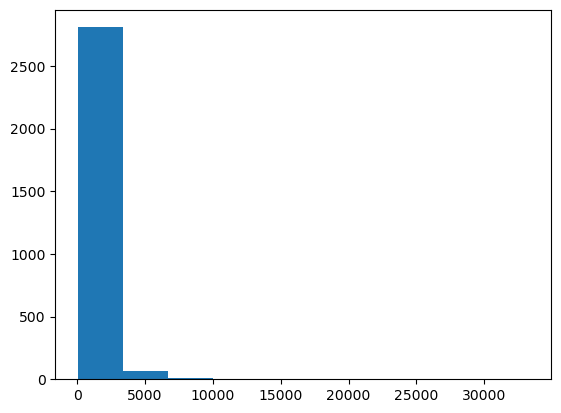

In [41]:
plt.hist(data['montant_dh'])

<Axes: ylabel='montant_dh'>

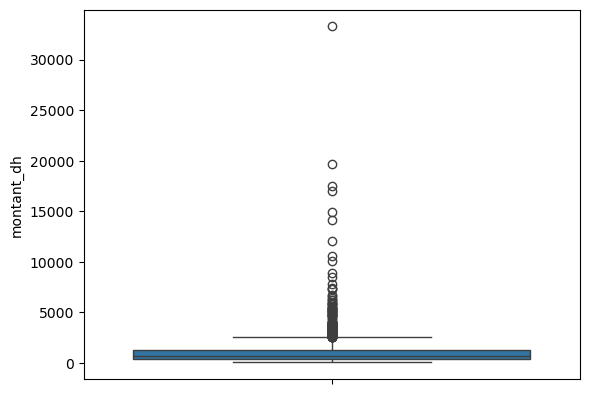

In [42]:
sns.boxplot(data['montant_dh'])

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


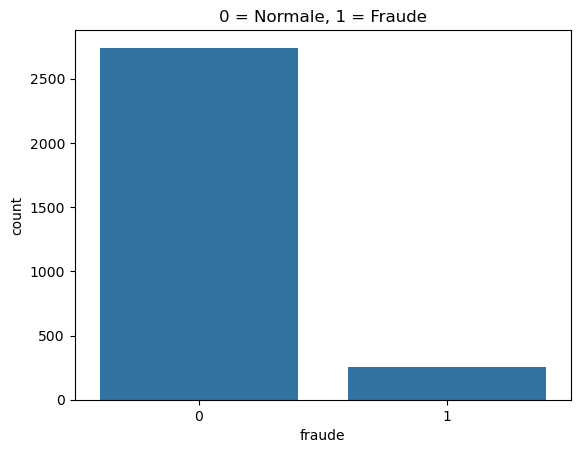

In [43]:
print(data['fraude'].value_counts(normalize=True)*100)
sns.countplot(x='fraude', data=data)
plt.title("0 = Normale, 1 = Fraude")
plt.show()

In [44]:
# n'est pas équilibré : environ 91.4% de 0 et 8.6% de 1. C'est important 
# car un modèle qui prédit toujours 0 aura 97% d'accuracy mais 0 fraude détectée. 
# Il faut donc regarder le rappel, la précision, le F1, et gérer le déséquilibre.

In [45]:
# 6 le variable resultat_enquete ne qu'un sens pour Explorer et vérifier les données

# Partie 2

### 7

In [46]:
cols_a_exclure = ['id_operation', 'id_client', 'resultat_enquete']
X = data.drop(columns=cols_a_exclure + ['fraude'])
y = data['fraude']

### 8

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", y_train.value_counts(normalize=True)*100)
print("Test:", y_test.value_counts(normalize=True)*100)

Train: fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64
Test: fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


### 9


In [49]:
num_cols = ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
cat_cols = ['canal', 'appareil', 'region', 'international']

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [51]:
pipe_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

pipe_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocess = ColumnTransformer([
    ('num', pipe_num, num_cols),
    ('cat', pipe_cat, cat_cols)
])

X_train_prep = preprocess.fit_transform(X_train)
X_test_prep = preprocess.transform(X_test)
print(f"Train: {X_train_prep.shape}, Test: {X_test_prep.shape}")

Train: (2400, 18), Test: (600, 18)


### 13

In [52]:
pipe_num_robust = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

preprocess_robust = ColumnTransformer([
    ('num', pipe_num_robust, num_cols),
    ('cat', pipe_cat, cat_cols)
])

X_train_r = preprocess_robust.fit_transform(X_train)
X_test_r = preprocess_robust.transform(X_test)
idx_montant = 0

### 14

# Partie 3

### 15

In [53]:
Q1 = X_train['montant_dh'].quantile(0.25)
Q3 = X_train['montant_dh'].quantile(0.75)
IQR = Q3 - Q1
print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}")

Q1=393.095, Q3=1249.8775, IQR=856.7825


### 16 

In [54]:
borne_inf = Q1 - 1.5*IQR
borne_sup = Q3 + 1.5*IQR
outliers = X_train[(X_train['montant_dh'] < borne_inf) | (X_train['montant_dh'] > borne_sup)]
print(f"Nombre d'outliers: {len(outliers)}")
print(outliers.head())

Nombre d'outliers: 146
      montant_dh  anciennete_mois  nb_ops_24h  heure        canal  appareil  \
1601     2940.62             22.0         3.0      9    telephone    mobile   
1348     3449.17            154.0         2.0     14          NaN  terminal   
2660    33281.23             34.0         4.0     17  application    mobile   
1489     3988.17            137.0         3.0     19       agence    mobile   
2049     3942.99            136.0         4.0     16  application    mobile   

                 region international  
1601  Casablanca-Settat           non  
1348  Casablanca-Settat           non  
2660              Autre           non  
1489  Casablanca-Settat           non  
2049     Draa-Tafilalet           non  


### 17

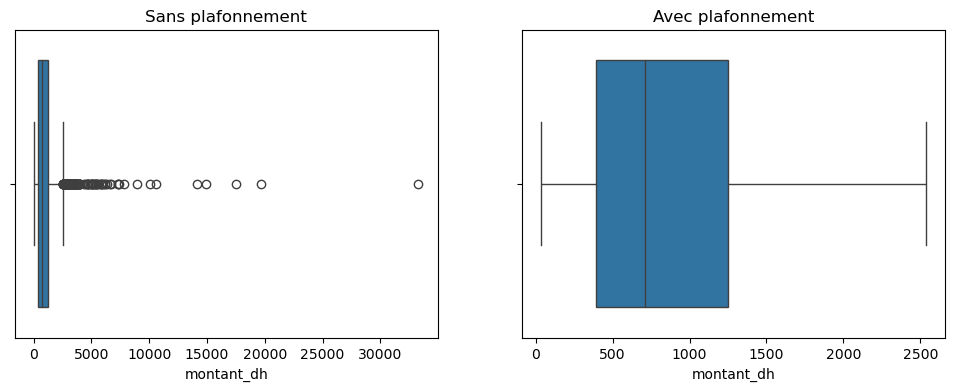

In [55]:

X_train_clip = X_train.copy()
X_train_clip['montant_dh'] = X_train_clip['montant_dh'].clip(borne_inf, borne_sup)
fig, axes = plt.subplots(1,2, figsize=(12,4))
sns.boxplot(x=X_train['montant_dh'], ax=axes[0]); axes[0].set_title("Sans plafonnement")
sns.boxplot(x=X_train_clip['montant_dh'], ax=axes[1]); axes[1].set_title("Avec plafonnement")
plt.show()

MinMax [4.92076660e-03 4.40246029e-02 1.49304162e-01 7.51887332e+00]
Standard [ -0.61607123   0.34599916   2.93618867 184.24945427]
Robust [ -0.59617231   0.92113226   5.00618302 290.95973599]


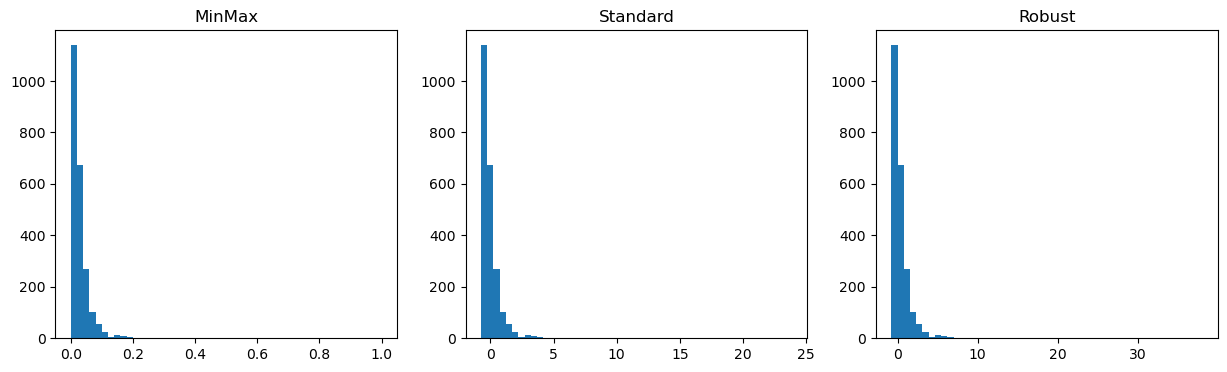

In [56]:
exemples = pd.DataFrame({'montant_dh': [200, 1500, 5000, 250000]})
for nom, scaler in [('MinMax', MinMaxScaler()), ('Standard', StandardScaler()), ('Robust', RobustScaler())]:
    scaler.fit(X_train[['montant_dh']])
    print(nom, scaler.transform(exemples).ravel())
fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax, (nom, scaler) in zip(axes, [('MinMax', MinMaxScaler()), ('Standard', StandardScaler()), ('Robust', RobustScaler())]):
    scaler.fit(X_train[['montant_dh']])
    vals = scaler.transform(X_train[['montant_dh']])
    ax.hist(vals, bins=50); ax.set_title(nom)
plt.show()

# Partie 4

### 22

In [57]:
print(y_train.value_counts())
ratio = y_train.value_counts()[0] / y_train.value_counts()[1]
print(f"Rapport 0/1 : {ratio:.1f} pour 1 fraude")

fraude
0    2194
1     206
Name: count, dtype: int64
Rapport 0/1 : 10.7 pour 1 fraude


### 23

In [58]:
from imblearn.over_sampling import RandomOverSampler

In [59]:
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train_prep, y_train)
print(pd.Series(y_train_ros).value_counts())

fraude
0    2194
1    2194
Name: count, dtype: int64
